# Moving average plot

In [8]:
# lib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Loading dataset
# 1 day data for disney from 1962-01-02 (earliest possible) to 2026-11-11
url = (
    "https://raw.githubusercontent.com/"
    "zhenyuwang0720/MA_Cross_Trading_Strategy_Analysis/"
    "main/data/DIS_1d_1962-01-02_2026-11-11.csv"
)

df = pd.read_csv(url)

print(df.head())

         Date        Open        High         Low       Close   Adj Close  \
0  2026-11-11  118.290001  119.220001  118.250000  118.750000  118.750000   
1  2026-11-10  118.690002  119.500000  117.419998  119.209999  119.209999   
2  2026-11-09  117.940002  119.379997  117.230003  119.120003  119.120003   
3  2026-11-06  114.440002  117.809998  113.790001  116.750000  116.750000   
4  2026-11-05  119.870003  120.800003  116.849998  117.220001  117.220001   

     Volume  
0    915986  
1   8000200  
2   7583300  
3   8576900  
4  11748100  


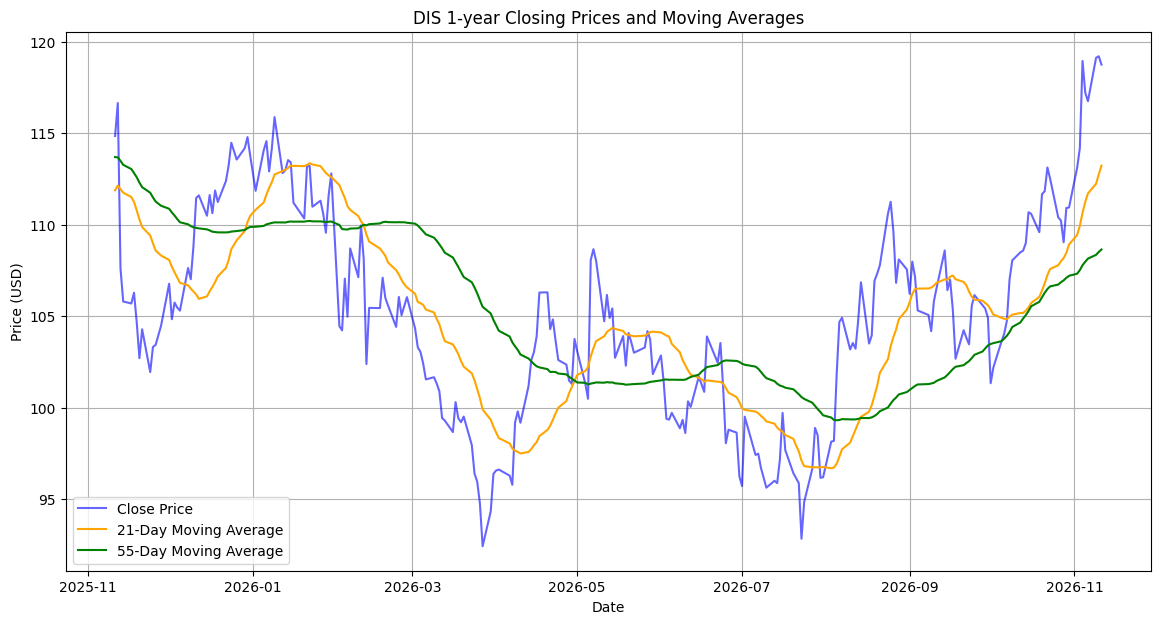

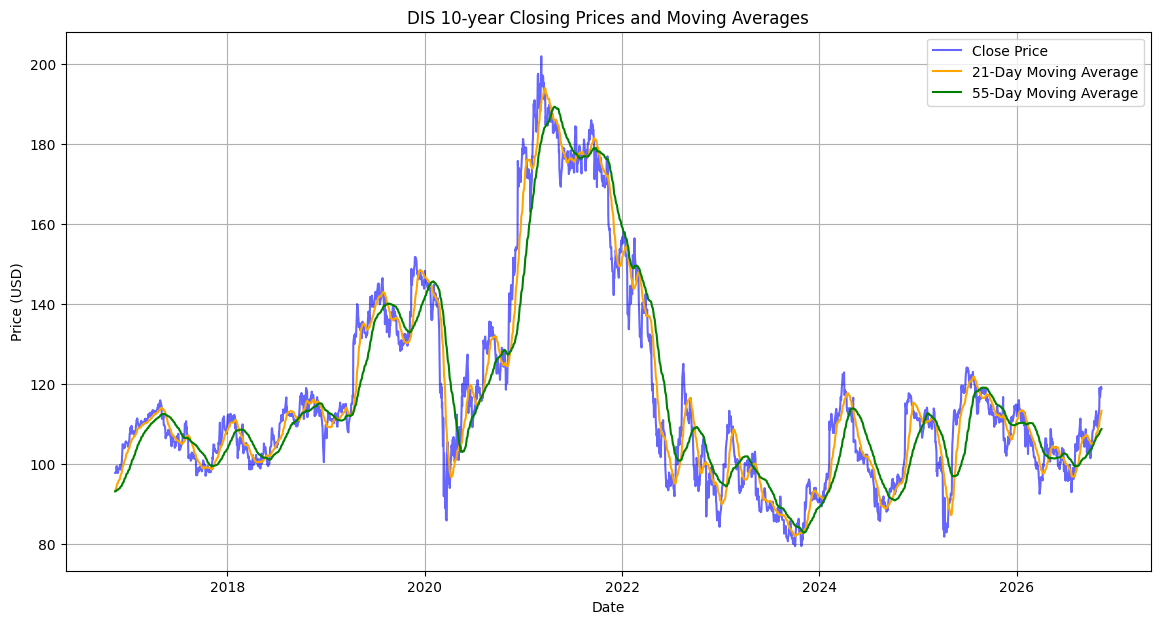

In [9]:
# Ensure date is parsed and sorted chronologically
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# Calculate moving averages (using fibonacci sequences)
df['MA21'] = df['Close'].rolling(window=21).mean()
df['MA34'] = df['Close'].rolling(window=34).mean()
df['MA55'] = df['Close'].rolling(window=55).mean()
df['MA89'] = df['Close'].rolling(window=89).mean()
df['MA144'] = df['Close'].rolling(window=144).mean()
df['MA233'] = df['Close'].rolling(window=233).mean()

### Label Golden Cross and Death Cross
# Golden_Cross: MA21>=MA55 while the previous day MA21<MA55
df['21above55'] = np.where(df['MA21'] >= df['MA55'], 1, 0)
# Golden Cross: Previous = 0, Current = 1
df['Golden_Cross'] = np.where(
    (df['21above55'] == 1) & (df['21above55'].shift(1) == 0),
    1, 0
)

# Death Cross: Previous = 1, Current = 0
df['Death_Cross'] = np.where(
    (df['21above55'] == 0) & (df['21above55'].shift(1) == 1),
    1, 0
)

### Focus on the recent 10 years
# Extract the data from latest 1 year (2026-11-11 to 2026-11-11)
df_1yr = df[df['Date'] >= '2025-11-11']
# Extract the data from latest 10 years (2016-11-11 to 2026-11-11)
df_10yr = df[df['Date'] >= '2016-11-11']

# Plotting 1 year
plt.figure(figsize=(14, 7))
plt.plot(df_1yr['Date'], df_1yr['Close'], label='Close Price', color='blue', alpha=0.6)
plt.plot(df_1yr['Date'], df_1yr['MA21'], label='21-Day Moving Average', color='orange')
plt.plot(df_1yr['Date'], df_1yr['MA55'], label='55-Day Moving Average', color='green')
plt.title('DIS 1-year Closing Prices and Moving Averages')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True)
plt.show()

# Plotting 10 year
plt.figure(figsize=(14, 7))
plt.plot(df_10yr['Date'], df_10yr['Close'], label='Close Price', color='blue', alpha=0.6)
plt.plot(df_10yr['Date'], df_10yr['MA21'], label='21-Day Moving Average', color='orange')
plt.plot(df_10yr['Date'], df_10yr['MA55'], label='55-Day Moving Average', color='green')
plt.title('DIS 10-year Closing Prices and Moving Averages')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True)
plt.show()

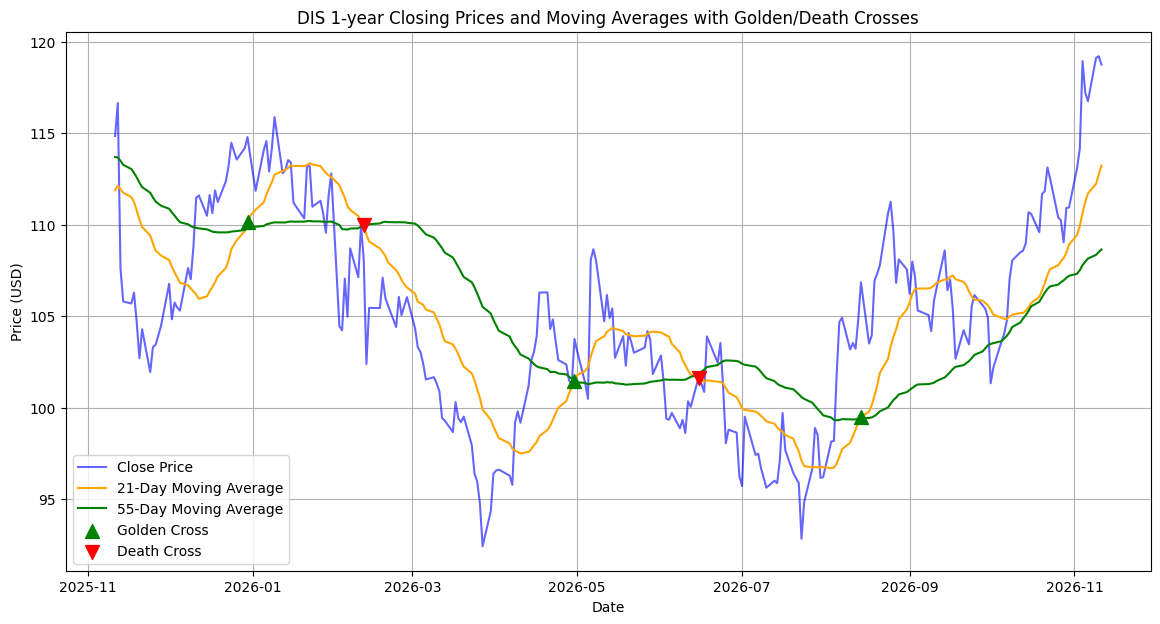

In [4]:
# Plot the Golden Cross and the DeathCross upon the Closing prices and Moving averages (MA21 and MA55)
# (1-year)
# Plotting Close and MAs
plt.figure(figsize=(14, 7))
plt.plot(df_1yr['Date'], df_1yr['Close'], label='Close Price', color='blue', alpha=0.6)
plt.plot(df_1yr['Date'], df_1yr['MA21'], label='21-Day Moving Average', color='orange')
plt.plot(df_1yr['Date'], df_1yr['MA55'], label='55-Day Moving Average', color='green')

# Dot Plotting Golden and Death Crosses
golden = df_1yr[df_1yr['Golden_Cross'] == 1]
death = df_1yr[df_1yr['Death_Cross'] == 1]
# Golden Cross dots
plt.scatter(golden['Date'], golden['MA21'],
            color='green', marker='^', s=100,
            label='Golden Cross', zorder=5)
# Death Cross dots
plt.scatter(death['Date'], death['MA21'],
            color='red', marker='v', s=100,
            label='Death Cross', zorder=5)
# Title and Label
plt.title('DIS 1-year Closing Prices and Moving Averages with Golden/Death Crosses')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True)
plt.show()


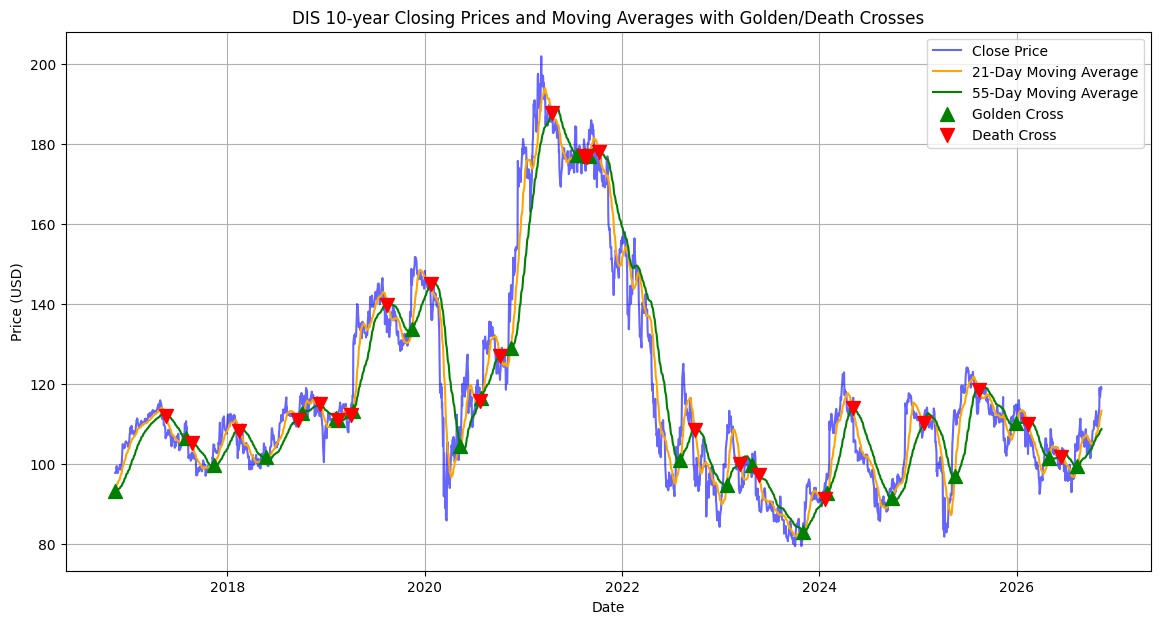

In [5]:
# Plot the Golden Cross and the DeathCross upon the Closing prices and Moving averages (MA21 and MA55)
# (10-year)
# Plotting Close and MAs
plt.figure(figsize=(14, 7))
plt.plot(df_10yr['Date'], df_10yr['Close'], label='Close Price', color='blue', alpha=0.6)
plt.plot(df_10yr['Date'], df_10yr['MA21'], label='21-Day Moving Average', color='orange')
plt.plot(df_10yr['Date'], df_10yr['MA55'], label='55-Day Moving Average', color='green')
# Dot Plotting Golden and Death Crosses
golden = df_10yr[df_10yr['Golden_Cross'] == 1]
death = df_10yr[df_10yr['Death_Cross'] == 1]
# Golden Cross dots
plt.scatter(golden['Date'], golden['MA21'],
            color='green', marker='^', s=100,
            label='Golden Cross', zorder=5)
# Death Cross dots
plt.scatter(death['Date'], death['MA21'],
            color='red', marker='v', s=100,
            label='Death Cross', zorder=5)
# Title and Label
plt.title('DIS 10-year Closing Prices and Moving Averages with Golden/Death Crosses')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True)
plt.show()


In [6]:
### Evaluation of the Golden/Death Cross Trading Strategy:
#-------------- Godlen/Death Cross Trading Strategy -----------#
# If a Golden Cross appears --> Buy at that day's closing price.
# Hold until the next Death Cross --> Sell at that day's closing price.
#-------------- Evaluation ------------------------------------#
# Calculate the percentage gain or loss.
# Repeat for every completed Golden Cross --> Death Cross interval.

# Evaluation of Golden Cross / Death Cross strategy

# initialization
trades = []
buy_date = None
buy_price = None

# going thru historical data and find out the completed trades based on the
# Golden/Death Cross Strategy
for i in range(len(df)):

    # Buy at Golden Cross
    if df.loc[i, 'Golden_Cross'] == 1 and buy_price is None:
        buy_date = df.loc[i, 'Date']
        buy_price = df.loc[i, 'Close']

    # Sell at next Death Cross
    elif df.loc[i, 'Death_Cross'] == 1 and buy_price is not None:
        sell_date = df.loc[i, 'Date']
        sell_price = df.loc[i, 'Close']

        # Calculate gain/loss (decimals)
        gain = (sell_price / buy_price - 1)

        # add the completed trade to the list
        trades.append({
            'Buy_Date': buy_date,
            'Buy_Price': buy_price,
            'Sell_Date': sell_date,
            'Sell_Price': sell_price,
            'Gain': gain
        })

        # Reset for next trade
        buy_date = None
        buy_price = None

# Convert to DataFrame
trades_df = pd.DataFrame(
    trades,
    columns=['Buy_Date', 'Buy_Price', 'Sell_Date',
             'Sell_Price', 'Gain']
)

# Print the trades
print(trades_df.to_string(
    index=True,
    columns=['Buy_Date', 'Buy_Price', 'Sell_Date',
             'Sell_Price', 'Gain'],
    formatters={'Gain': lambda x: f'{x:+.2%}'}
))


      Buy_Date   Buy_Price  Sell_Date  Sell_Price     Gain
0   1962-03-20    0.096650 1962-03-23    0.094155   -2.58%
1   1962-08-22    0.079502 1962-09-27    0.065472  -17.65%
2   1962-11-23    0.074826 1963-04-29    0.086383  +15.45%
3   1963-05-10    0.091521 1963-11-18    0.104045  +13.68%
4   1964-02-13    0.105329 1964-05-26    0.110789   +5.18%
5   1964-07-27    0.108862 1964-08-17    0.102760   -5.61%
6   1964-09-11    0.116890 1964-12-02    0.115605   -1.10%
7   1965-01-18    0.123313 1965-04-26    0.143222  +16.15%
8   1965-05-10    0.146112 1965-06-16    0.132946   -9.01%
9   1965-08-17    0.133267 1965-09-13    0.125882   -5.54%
10  1965-10-25    0.137442 1966-02-25    0.143543   +4.44%
11  1966-04-29    0.146755 1966-05-19    0.131662  -10.28%
12  1966-07-06    0.136158 1966-08-03    0.131662   -3.30%
13  1966-10-28    0.141296 1967-03-03    0.216439  +53.18%
14  1967-03-15    0.219650 1967-07-20    0.227357   +3.51%
15  1967-09-12    0.241487 1968-01-15    0.290298  +20.2

In [7]:
# Calculate the Gain/Loss for the most recent 10 years
df_10yr_trades = trades_df[trades_df['Buy_Date'] >= '2016-11-11'].reset_index(drop=True)
# Calculate the cummulative Gain/loss for the recent 10 years
for i in range(len(df_10yr_trades)):
    if i == 0:
        df_10yr_trades.loc[i, 'Cum_Gain'] = df_10yr_trades.loc[i, 'Gain']
    else:
        df_10yr_trades.loc[i, 'Cum_Gain'] = (1+df_10yr_trades.loc[i-1,
        'Cum_Gain'])*(1 + df_10yr_trades.loc[i, 'Gain'])-1

# Print some summaries of the 24 trades within the 10 years
print(df_10yr_trades.to_string(
    index=True,
    columns=['Buy_Date', 'Buy_Price', 'Sell_Date',
             'Sell_Price', 'Gain', 'Cum_Gain'],
    formatters={'Gain': lambda x: f'{x:+.2%}',
                'Cum_Gain': lambda x: f'{x:+.2%}'}
))
# Print the actual stock price gain/loss over the 10 year interval,
# assume we buy on the Buy_Price of the first trade and sell on the Sell_Price of the last trade
Interval_Starting_Price = df_10yr_trades.loc[0, 'Buy_Price']
Interval_Ending_Price = df_10yr_trades.loc[len(df_10yr_trades)-1, 'Sell_Price']
Interval_Gain = (Interval_Ending_Price/Interval_Starting_Price-1)
# Compare the Golden/Death Trading Strategy with the Interval_Gain
print("------------------------------------------------------------------")
print(f"Number of successful Golden-Death trades: {len(df_10yr_trades)}")
print("Golden-Death Strategy Average Gain: " + f'{df_10yr_trades["Gain"].mean():+.2%}')
print("Golden-Death Strategy Cummulative Gain: " + f'{df_10yr_trades["Cum_Gain"].iloc[-1]:+.2%}')
print("Close price change: " + f'{Interval_Gain:+.2%}')
print("Strategy advantage: " + f'{(df_10yr_trades["Cum_Gain"].iloc[-1] - Interval_Gain):+.2%}')
print("------------------------------------------------------------------")

#

     Buy_Date   Buy_Price  Sell_Date  Sell_Price    Gain Cum_Gain
0  2016-11-11   97.680000 2017-05-18  106.680000  +9.21%   +9.21%
1  2017-08-02  108.669998 2017-08-22  102.769997  -5.43%   +3.28%
2  2017-11-13  104.739998 2018-02-14  104.599998  -0.13%   +3.15%
3  2018-05-22  104.070000 2018-09-19  109.790001  +5.50%   +8.82%
4  2018-10-05  114.779999 2018-12-10  111.860001  -2.54%   +6.05%
5  2019-02-06  111.410004 2019-02-14  110.660004  -0.67%   +5.33%
6  2019-02-15  112.589996 2019-04-05  115.000000  +2.14%   +7.59%
7  2019-04-12  130.059998 2019-08-16  135.199997  +3.95%  +11.84%
8  2019-11-14  147.149994 2020-01-23  142.199997  -3.36%   +8.08%
9  2020-05-12  104.559998 2020-07-23  118.120003 +12.97%  +22.09%
10 2020-07-28  116.180000 2020-10-07  122.910004  +5.79%  +29.17%
11 2020-11-16  144.669998 2021-04-16  187.259995 +29.44%  +67.19%
12 2021-07-20  176.750000 2021-08-13  181.080002  +2.45%  +71.29%
13 2021-08-17  175.830002 2021-08-25  178.309998  +1.41%  +73.70%
14 2021-08